# Подготовка данных

In [ ]:
pip install git+https://github.com/Mvin8/PopFrame.git@test

In [ ]:
data_path = '/content/data' # в эту папку нужно положить данные

In [ ]:
from popframe.models.region import Region
import os
import warnings
import geopandas as gpd
import pandas as pd
warnings.filterwarnings("ignore") # отключаем все предупреждения

region_model = Region.from_pickle(os.path.join(data_path, 'Ленинградская область.pickle')) # считываем в переменную готовую модель региона

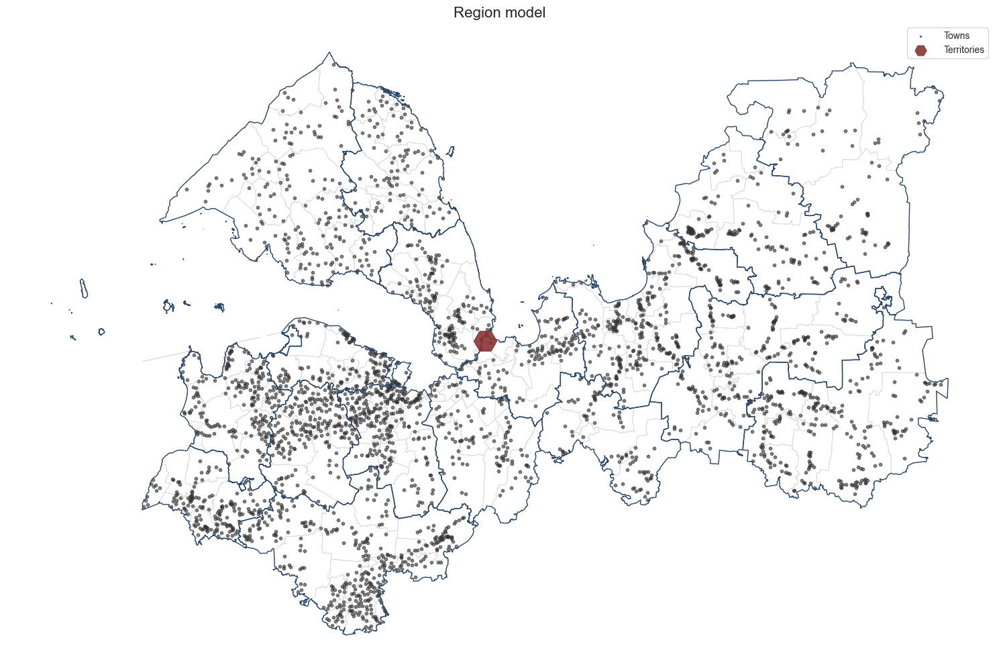

In [ ]:
gdf_hex = gpd.read_file(os.path.join(data_path,'LO_hex.geojson')) # считываем в переменную гексагоны
gdf_hex.explore()

In [ ]:
territory = gdf_hex[gdf_hex['id'] == 1632] # указать id выбранной вами территории
territory.explore()

# Оценка населения територии

In [ ]:
from popframe.method.territory_evaluation import TerritoryEvaluation

evaluation = TerritoryEvaluation(region=region_model)

results = evaluation.population_criterion(territories_gdf=territory)
results

[{'project': None,
  'average_population_density': 19.2,
  'total_population': 41871,
  'score': 4.0,
  'interpretation': 'Территория имеет хорошие показатели численности и плотности населения, что способствует ее активному развитию.'}]

In [ ]:
results = evaluation.population_criterion(territories_gdf=gdf_hex)
scores_df = pd.DataFrame(results)

scores_df

,project,average_population_density,total_population,score,interpretation
0,None,1.0,2161,2.0,Территория имеет умеренные показатели численно...
1,None,0.1,313,1.0,Территория имеет малые показатели численности ...
2,None,139.9,307578,5.0,Территория с высокими показателями численности...
3,None,0.0,15,1.0,Территория имеет малые показатели численности ...
4,None,1.9,4221,2.0,Территория имеет умеренные показатели численно...
...,...,...,...,...,...
2143,None,2.4,5328,3.0,Территория имеет показатели численности и плот...
2144,None,0.1,120,1.0,Территория имеет малые показатели численности ...
2145,None,1.9,4232,2.0,Территория имеет умеренные показатели численно...
2146,None,9.4,20684,3.0,Территория имеет показатели численности и плот...


In [ ]:
gdf_hex['score_1'] = scores_df['score']
gdf_hex

,id,geometry,score_1
0,0,"POLYGON ((29.65352 60.75606, 29.69198 60.73276...",2.0
1,1,"POLYGON ((34.21298 59.70612, 34.24864 59.6808,...",1.0
2,2,"POLYGON ((30.54114 59.98839, 30.57846 59.96455...",5.0
3,3,"POLYGON ((34.68571 60.95192, 34.72244 60.92676...",1.0
4,4,"POLYGON ((34.5092 59.59026, 34.54462 59.5648, ...",2.0
...,...,...,...
2143,2143,"POLYGON ((28.90861 60.56897, 28.9471 60.54592,...",3.0
2144,2144,"POLYGON ((32.84355 59.76933, 32.87981 59.74454...",1.0
2145,2145,"POLYGON ((32.53064 59.24881, 32.5665 59.22401,...",2.0
2146,2146,"POLYGON ((30.05365 60.38205, 30.09156 60.3585,...",3.0


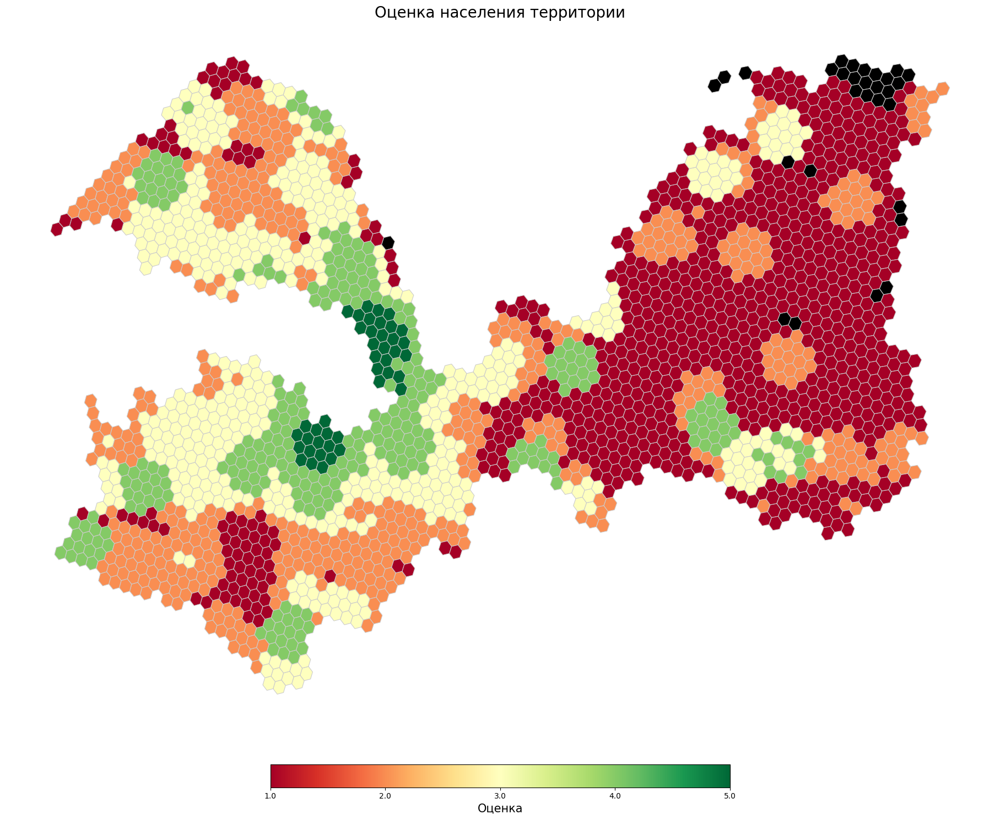

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.cm as cm
import numpy as np

# Определяем цветовую карту: от красного (низкий score) к зелёному (высокий score)
cmap = cm.get_cmap('RdYlGn')

# Определяем минимальное и максимальное значение для нормализации
vmin = 1  # Минимальная оценка
vmax = gdf_hex['score_1'].max()  # Максимальная оценка
norm = colors.Normalize(vmin=vmin, vmax=vmax)

# Настраиваем шаг 0.5
ticks = np.arange(vmin, vmax + 1, 1)

# Создаем фигуру
fig, ax = plt.subplots(1, 1, figsize=(30, 15))  # Увеличенный размер карты

# Применяем цвета к каждой области
gdf_hex['color'] = gdf_hex['score_1'].apply(
    lambda score: 'black' if score == 0 else cmap(norm(score))
)

# Визуализируем с раскраской по значению 'color'
gdf_hex.plot(color=gdf_hex['color'], linewidth=0.8, ax=ax, edgecolor='0.8')

# Добавляем цветовую шкалу
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm._A = []  # Это нужно, чтобы ScalarMappable работал корректно
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.03, pad=0.05)
cbar.set_label('Оценка', fontsize=15)
cbar.set_ticks(ticks)  # Устанавливаем деления на шкале
cbar.ax.set_xticklabels([f"{tick:.1f}" for tick in ticks])  # Форматируем подписи

# Убираем оси
ax.set_axis_off()

# Добавляем заголовок
ax.set_title('Оценка населения территории', fontsize=20)

# Настраиваем автоматическую компоновку
plt.tight_layout()

# Показываем карту
plt.show()

# Оценка расположения територии

In [ ]:
from popframe.method.territory_evaluation import TerritoryEvaluation
evaluation = TerritoryEvaluation(region=region_model)
result = evaluation.evaluate_territory_location(territories_gdf=territory)
result

[{'territory': 'None',
  'score': 2.5,
  'interpretation': 'Территория находится внутри или непосредственной близости населенного пункта уровня Малый город',
  'closest_settlement': 'Сиверский',
  'closest_settlement1': None,
  'closest_settlement2': None}]

In [ ]:
results = evaluation.evaluate_territory_location(territories_gdf=gdf_hex)
scores_df = pd.DataFrame(results)
scores_df

,territory,score,interpretation,closest_settlement,closest_settlement1,closest_settlement2
0,None,1.5,Территория находится внутри или непосредственн...,Ромашки,None,None
1,None,0.5,Территория находится внутри или непосредственн...,Казённое Село,None,None
2,None,3.0,Территория находится внутри или непосредственн...,Всеволожск,None,None
3,None,0.5,Территория находится внутри или непосредственн...,Пидьма,None,None
4,None,0.5,Территория находится внутри или непосредственн...,Рязанский Шлюз,None,None
...,...,...,...,...,...,...
2143,None,1.5,Территория находится внутри или непосредственн...,Гаврилово,None,None
2144,None,0.5,Территория находится внутри или непосредственн...,Зеленец (поселок),None,None
2145,None,0.5,Территория находится внутри или непосредственн...,Бестоголово,None,None
2146,None,2.5,Территория находится внутри или непосредственн...,Лемболово (поселок при ж/д),None,None


In [ ]:
gdf_hex['score_2'] = scores_df['score']
gdf_hex

,id,geometry,score_1,color,score_2
0,0,"POLYGON ((29.65352 60.75606, 29.69198 60.73276...",2.0,"(0.9748558246828143, 0.5574009996155325, 0.322...",1.5
1,1,"POLYGON ((34.21298 59.70612, 34.24864 59.6808,...",1.0,"(0.6470588235294118, 0.0, 0.14901960784313725,...",0.5
2,2,"POLYGON ((30.54114 59.98839, 30.57846 59.96455...",5.0,"(0.0, 0.40784313725490196, 0.21568627450980393...",3.0
3,3,"POLYGON ((34.68571 60.95192, 34.72244 60.92676...",1.0,"(0.6470588235294118, 0.0, 0.14901960784313725,...",0.5
4,4,"POLYGON ((34.5092 59.59026, 34.54462 59.5648, ...",2.0,"(0.9748558246828143, 0.5574009996155325, 0.322...",0.5
...,...,...,...,...,...
2143,2143,"POLYGON ((28.90861 60.56897, 28.9471 60.54592,...",3.0,"(0.9970780469050365, 0.9987697039600154, 0.745...",1.5
2144,2144,"POLYGON ((32.84355 59.76933, 32.87981 59.74454...",1.0,"(0.6470588235294118, 0.0, 0.14901960784313725,...",0.5
2145,2145,"POLYGON ((32.53064 59.24881, 32.5665 59.22401,...",2.0,"(0.9748558246828143, 0.5574009996155325, 0.322...",0.5
2146,2146,"POLYGON ((30.05365 60.38205, 30.09156 60.3585,...",3.0,"(0.9970780469050365, 0.9987697039600154, 0.745...",2.5


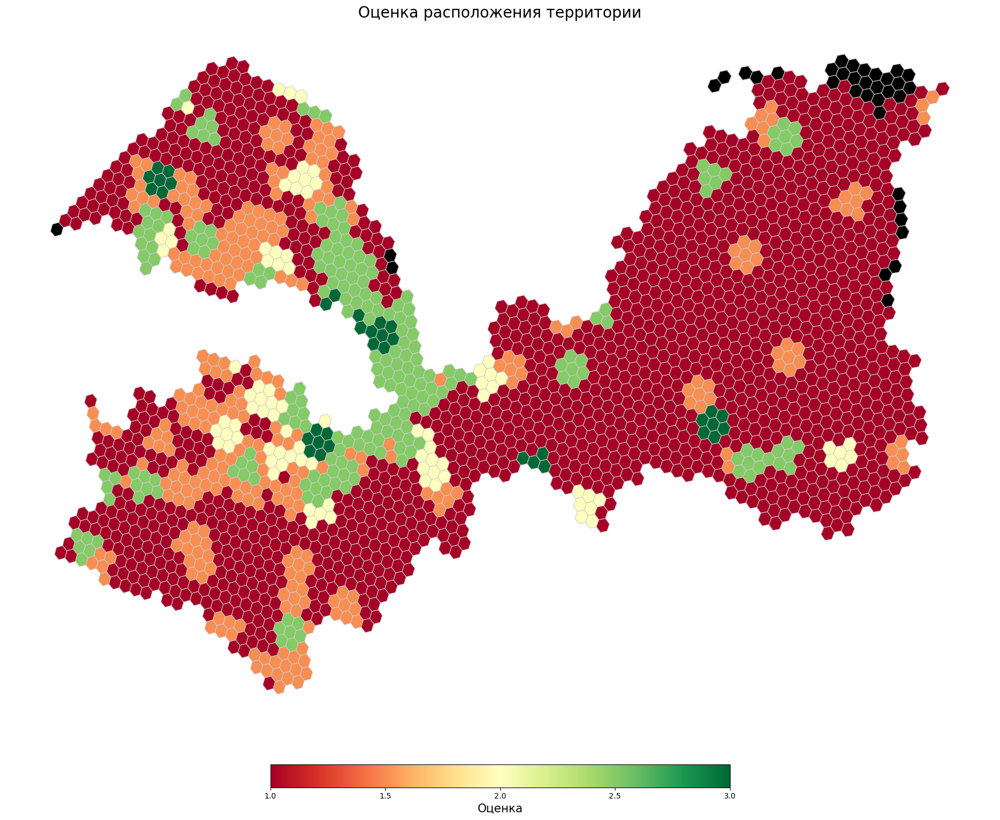

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.cm as cm
import numpy as np

# Определяем цветовую карту: от красного (низкий score) к зелёному (высокий score)
cmap = cm.get_cmap('RdYlGn')

# Определяем минимальное и максимальное значение для нормализации
vmin = 1  # Минимальная оценка
vmax = gdf_hex['score_2'].max()  # Максимальная оценка
norm = colors.Normalize(vmin=vmin, vmax=vmax)

# Настраиваем шаг 0.5
ticks = np.arange(vmin, vmax + 0.5, 0.5)

# Создаем фигуру
fig, ax = plt.subplots(1, 1, figsize=(30, 15))  # Увеличенный размер карты

# Применяем цвета к каждой области
gdf_hex['color'] = gdf_hex['score_2'].apply(
    lambda score: 'black' if score == 0 else cmap(norm(score))
)

# Визуализируем с раскраской по значению 'color'
gdf_hex.plot(color=gdf_hex['color'], linewidth=0.8, ax=ax, edgecolor='0.8')

# Добавляем цветовую шкалу
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm._A = []  # Это нужно, чтобы ScalarMappable работал корректно
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=0.03, pad=0.05)
cbar.set_label('Оценка', fontsize=15)
cbar.set_ticks(ticks)  # Устанавливаем деления на шкале
cbar.ax.set_xticklabels([f"{tick:.1f}" for tick in ticks])  # Форматируем подписи

# Убираем оси
ax.set_axis_off()

# Добавляем заголовок
ax.set_title('Оценка расположения территории', fontsize=20)

# Настраиваем автоматическую компоновку
plt.tight_layout()

# Показываем карту
plt.show()

# Определение типов землепользования

In [ ]:
from popframe.method.landuse_assessment import LandUseAssessment
landuse = LandUseAssessment(region=region_model)
landuse_data = landuse.get_landuse_data(territory)
landuse_data




Processing landuse tags: 100%|██████████| 37/37 [01:55<00:00,  3.13s/it]
<frozen importlib._bootstrap>:914: ImportWarning: _PyDrive2ImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _PyDriveImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _GenerativeAIImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _OpenCVImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: APICoreClientInfoImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _BokehImportHook.find_spec() not found; falling back to find_module()
<frozen importlib._bootstrap>:914: ImportWarning: _AltairImportHook.find_spec() not found; falling back to find_module()
sys:1: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) 

,№ п/п,Название хранимое,ед.изм.,Значение,Источник,Период,geometry
0,1.3.1,Процент застройки жилищным строительством,%,1.964,modeled,2024,"MULTIPOLYGON (((30.13608 59.34606, 30.13588 59..."
1,1.3.2,Процент земель сельскохозяйственного назначения,%,24.118,modeled,2024,"MULTIPOLYGON (((30.07342 59.3324, 30.0735 59.3..."
2,1.3.3,Процент земель промышленного назначения,%,1.502,modeled,2024,"MULTIPOLYGON (((30.06392 59.35034, 30.06373 59..."
3,1.3.4,"Процент земель, занятых лесными массивами",%,24.942,modeled,2024,"MULTIPOLYGON (((30.05792 59.34254, 30.05777 59..."
4,1.3.5,Процент земель специального назначения,%,3.715,modeled,2024,"MULTIPOLYGON (((30.04956 59.35085, 30.04979 59..."
5,1.3.6,Процент земель населенных пунктов,%,24.009,modeled,2024,"MULTIPOLYGON (((30.0581 59.3433, 30.05805 59.3..."
6,1.3.8,"Процент земель, занятых водным фондом",%,1.036,modeled,2024,"MULTIPOLYGON (((30.07246 59.34834, 30.07265 59..."
7,1.3.9,Территории смежного назначения,%,18.711,modeled,2024,"MULTIPOLYGON (((30.0735 59.33232, 30.07342 59...."


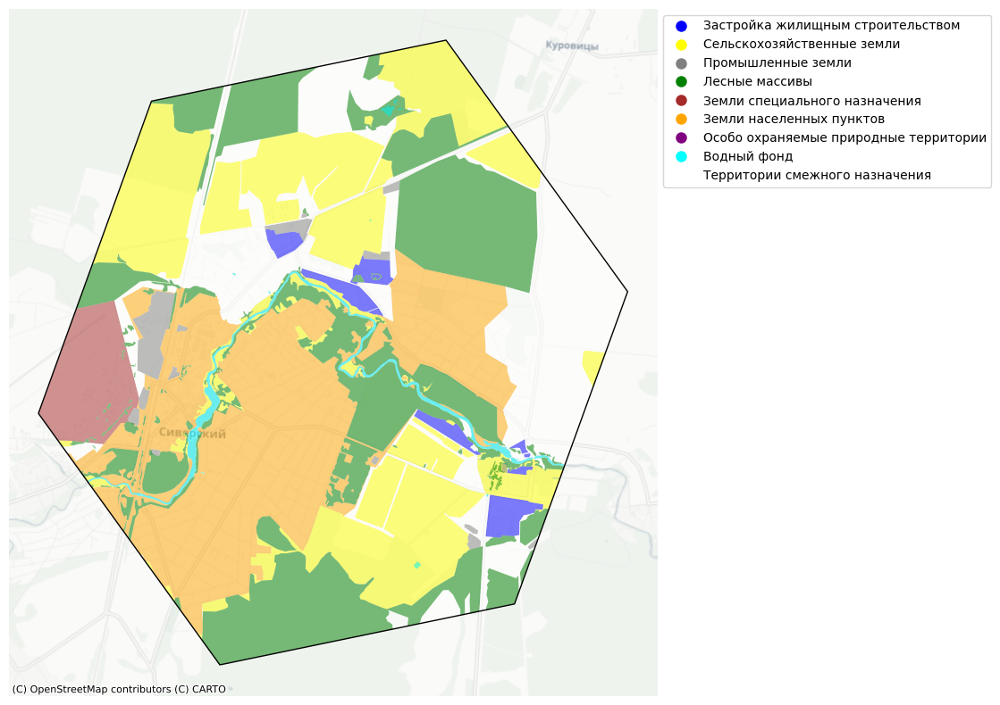

In [ ]:
# Визуализация получившихся типов землепользования
landuse.plot_landuse(territory, landuse_data)

# Потенциал територии

In [ ]:
from popframe.method.territory_evaluation import TerritoryEvaluation

territories_criteria = {
        "Население": 4,
        "Транспорт": 4,
        "Экология": 3,
        "Соц-об": 3,
        "Инж инф": 2,
    }

ranked_profiles = evaluation.calculate_potential(territories_criteria)
for profile, (potential, weighted_score) in ranked_profiles:
        print(f"Профиль: {profile}, Потенциал: {potential}")

Профиль: Специального назначения, Потенциал: 5
Профиль: Транспортная инженерная, Потенциал: 5
Профиль: Промышленная, Потенциал: 4
Профиль: Жилая застройка - Малоэтажная, Потенциал: 3
Профиль: Сельско-хозяйственная, Потенциал: 3
Профиль: Жилая застройка - Среднеэтажная, Потенциал: 3
Профиль: Жилая застройка - ИЖС, Потенциал: 2
Профиль: Общественно-деловая, Потенциал: 2
Профиль: Жилая застройка - Многоэтажная, Потенциал: 1
Профиль: Рекреационная, Потенциал: 4


# Агломерация

In [ ]:
from popframe.method.aglomeration import AgglomerationBuilder

agglomeration_builder = AgglomerationBuilder(region=region_model)
final_agglomerations = agglomeration_builder.get_agglomerations()
final_agglomerations

/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["left_distance"]).unary_union
/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["left_distance"]).unary_union
/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["left_distance"]).unary_union
/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["l

,type,core_cities,population,agglomeration_level,geometry
0,Polycentric,"Бугры, Кудрово, Кировск, Всеволожск, Коммунар,...",1135898,4,"POLYGON ((309323.569 6587367.083, 309263.482 6..."
1,Polycentric,"Светогорск, Выборг",152555,1,"POLYGON ((259737.666 6699229.803, 259598.016 6..."
2,Polycentric,"Тихвин, Пикалево, Бокситогорск",109218,1,"POLYGON ((533870.027 6582969.462, 533888.029 6..."
3,Polycentric,"Кириши, Волхов",102549,1,"POLYGON ((418840.032 6582201.177, 418794.336 6..."
4,Polycentric,"Сланцы, Кингисепп",115886,1,"POLYGON ((204694.455 6552211.508, 204618.572 6..."
5,Monocentric,Луга,58903,1,"POLYGON ((306699.036 6486351.221, 306591.758 6..."
6,Polycentric,"Лодейное Поле, Подпорожье",44634,1,"POLYGON ((510939.184 6710445.665, 510785.306 6..."
7,Monocentric,Приозерск,30541,1,"POLYGON ((337076.979 6743413.735, 336818.646 6..."


In [ ]:
final_agglomerations.explore()

In [ ]:
from popframe.method.popuation_frame import PopulationFrame
frame_method = PopulationFrame(region=region_model)
cities = frame_method.build_circle_frame()
cities

,id,name,population,level,geometry
0,0,Болото,10,Малое сельское поселение,"POLYGON ((543177.545 6580637.216, 543177.376 6..."
1,1,Большой Остров,68,Малое сельское поселение,"POLYGON ((544624.73 6593227.683, 544624.288 65..."
2,2,Бор,1734,Большое сельское поселение,"POLYGON ((545358.957 6593052.346, 545356.725 6..."
3,3,Бороватое,10,Малое сельское поселение,"POLYGON ((544028.318 6589581.591, 544028.148 6..."
4,4,Бочево,10,Малое сельское поселение,"POLYGON ((538575.316 6576793.156, 538575.147 6..."
...,...,...,...,...,...
2925,2925,Апраксин Бор,313,Среднее сельское поселение,"POLYGON ((399256.679 6560340.947, 399255.73 65..."
2926,2926,Александровка,313,Среднее сельское поселение,"POLYGON ((404164.108 6562086.557, 404163.159 6..."
2927,2927,Большая Горка,313,Среднее сельское поселение,"POLYGON ((413313.678 6573792.753, 413312.73 65..."
2928,2928,Дроздово,5,Малое сельское поселение,"POLYGON ((412482.916 6574810.78, 412482.796 65..."


In [ ]:
cities.explore()

In [ ]:
cities_with_status = agglomeration_builder.evaluate_city_agglomeration_status(cities, final_agglomerations)
cities_with_status

,id,name,population,level,geometry,agglomeration_status,agglomeration_level
0,0,Болото,10,Малое сельское поселение,"POLYGON ((543177.545 6580637.216, 543177.376 6...",В агломерации,1
1,1,Большой Остров,68,Малое сельское поселение,"POLYGON ((544624.73 6593227.683, 544624.288 65...",В агломерации,1
2,2,Бор,1734,Большое сельское поселение,"POLYGON ((545358.957 6593052.346, 545356.725 6...",В агломерации,1
3,3,Бороватое,10,Малое сельское поселение,"POLYGON ((544028.318 6589581.591, 544028.148 6...",В агломерации,1
4,4,Бочево,10,Малое сельское поселение,"POLYGON ((538575.316 6576793.156, 538575.147 6...",В агломерации,1
...,...,...,...,...,...,...,...
2925,2925,Апраксин Бор,313,Среднее сельское поселение,"POLYGON ((399256.679 6560340.947, 399255.73 65...",Вне агломерации,0
2926,2926,Александровка,313,Среднее сельское поселение,"POLYGON ((404164.108 6562086.557, 404163.159 6...",Вне агломерации,0
2927,2927,Большая Горка,313,Среднее сельское поселение,"POLYGON ((413313.678 6573792.753, 413312.73 65...",Вне агломерации,0
2928,2928,Дроздово,5,Малое сельское поселение,"POLYGON ((412482.916 6574810.78, 412482.796 65...",Вне агломерации,0


<ipython-input-27-e66d8ba19560>:42: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, color=color, edgecolor='black')
<ipython-input-27-e66d8ba19560>:42: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, color=color, edgecolor='black')
<ipython-input-27-e66d8ba19560>:47: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, marker='o', color=color, markersize=10, edgecolor='black')


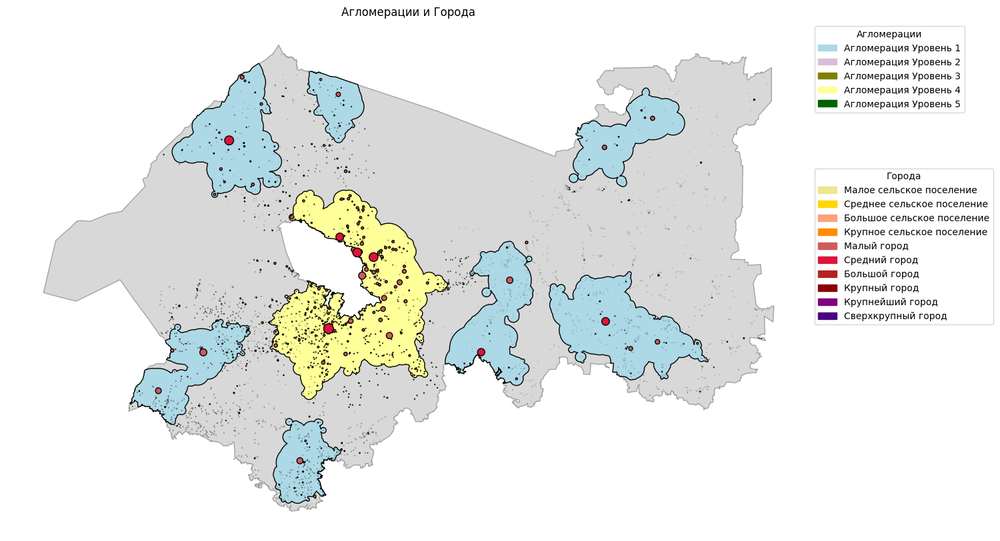

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Ваши цвета для агломераций
agglomeration_colors = {
    1: "#ADD8E6",  # светло-голубой
    2: "#D8BFD8",  # светло-фиолетовый
    3: "#808000",  # оливковый
    4: "#FFFF99",  # светло-желтый
    5: "#006400"   # темно-зеленый
}

# Ваши цвета для городов
city_colors = {
    "Малое сельское поселение": "#F0E68C",  # бледно-желтый
    "Среднее сельское поселение": "#FFD700",  # золотисто-желтый
    "Большое сельское поселение": "#FFA07A",  # светло-лососевый
    "Крупное сельское поселение": "#FF8C00",  # темно-оранжевый
    "Малый город": "#CD5C5C",                 # красно-коричневый
    "Средний город": "#DC143C",               # красный кармин
    "Большой город": "#B22222",               # огненно-красный
    "Крупный город": "#8B0000",               # темно-красный
    "Крупнейший город": "#800080",            # фиолетовый
    "Сверхкрупный город": "#4B0082"           # индиго
}

# Чтение агломераций и городов из GeoDataFrame
gdf_agglomerations = final_agglomerations
gdf_cities = cities
region_boundary = region_model.region  # Ваши границы региона

# Создание подложки для карты
fig, ax = plt.subplots(figsize=(20, 10))

# Визуализация границ региона (серым цветом с прозрачностью)
region_boundary.plot(ax=ax, color='gray', edgecolor='black', alpha=0.3)

# Визуализация агломераций
for level, color in agglomeration_colors.items():
    subset = gdf_agglomerations[gdf_agglomerations['agglomeration_level'] == level]
    subset.plot(ax=ax, color=color, edgecolor='black')

# Визуализация городов с различными цветами
for city_type, color in city_colors.items():
    subset = gdf_cities[gdf_cities['level'] == city_type]
    subset.plot(ax=ax, marker='o', color=color, markersize=10, edgecolor='black')

# Создание легенды для агломераций
agglomeration_patches = [mpatches.Patch(color=color, label=f'Агломерация Уровень {level}')
                         for level, color in agglomeration_colors.items()]

# Создание легенды для городов
city_patches = [mpatches.Patch(color=color, label=city_type)
                for city_type, color in city_colors.items()]

# Отображение легенды для агломераций
legend_agglomeration = plt.legend(handles=agglomeration_patches, loc='upper left', bbox_to_anchor=(1, 1), title="Агломерации")
ax.add_artist(legend_agglomeration)  # Добавление первой легенды

# Отображение легенды для городов
plt.legend(handles=city_patches, loc='lower left', bbox_to_anchor=(1, 0.4), title="Города")

# Настройка осей
plt.title("Агломерации и Города")
ax.set_axis_off()

# Показать карту
plt.show()

## Сценарии

In [ ]:
import pandas as pd
# update = {
#     630: {
#         'population': 300_000,
#     },
#     259: {
#         'population': 150_000,
#     }
# }

update = {
  1874: {
    'population': 1_000_000,
  }
}
update_df = pd.DataFrame.from_dict(update, orient='index')

/usr/local/lib/python3.10/dist-packages/ipykernel/ipkernel.py:283: DeprecationWarning: `should_run_async` will not call `transform_cell` automatically in the future. Please pass the result to `transformed_cell` argument and any exception that happen during thetransform in `preprocessing_exc_tuple` in IPython 7.17 and above.
  and should_run_async(code)


In [ ]:
final_agglomerations = agglomeration_builder.get_agglomerations(update_df)
final_agglomerations

/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["left_distance"]).unary_union
/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["left_distance"]).unary_union
/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["left_distance"]).unary_union
/usr/local/lib/python3.10/dist-packages/popframe/method/aglomeration.py:93: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  agglomeration_geom = nodes_gdf.buffer(nodes_gdf["l

,type,core_cities,population,agglomeration_level,geometry
0,Polycentric,"Луга, Бугры, Кудрово, Кингисепп, Кировск, Слан...",2251367,4,"POLYGON ((204694.455 6552211.508, 204618.572 6..."
1,Polycentric,"Светогорск, Выборг",152555,1,"POLYGON ((259737.666 6699229.803, 259598.016 6..."
2,Polycentric,"Тихвин, Пикалево, Бокситогорск",109218,1,"POLYGON ((533870.027 6582969.462, 533888.029 6..."
3,Polycentric,"Кириши, Волхов",102549,1,"POLYGON ((418840.032 6582201.177, 418794.336 6..."
4,Polycentric,"Лодейное Поле, Подпорожье",44634,1,"POLYGON ((510939.184 6710445.665, 510785.306 6..."
5,Monocentric,Приозерск,30541,1,"POLYGON ((337076.979 6743413.735, 336818.646 6..."


In [ ]:
from popframe.method.popuation_frame import PopulationFrame
frame_method = PopulationFrame(region=region_model)
cities = frame_method.build_circle_frame(update_df)
cities

,geometry,id,name,population,level
0,"POLYGON ((543177.545 6580637.216, 543177.376 6...",0,Болото,10,Малое сельское поселение
1,"POLYGON ((544624.73 6593227.683, 544624.288 65...",1,Большой Остров,68,Малое сельское поселение
2,"POLYGON ((545358.957 6593052.346, 545356.725 6...",2,Бор,1734,Большое сельское поселение
3,"POLYGON ((544028.318 6589581.591, 544028.148 6...",3,Бороватое,10,Малое сельское поселение
4,"POLYGON ((538575.316 6576793.156, 538575.147 6...",4,Бочево,10,Малое сельское поселение
...,...,...,...,...,...
2925,"POLYGON ((399256.679 6560340.947, 399255.73 65...",2925,Апраксин Бор,313,Среднее сельское поселение
2926,"POLYGON ((404164.108 6562086.557, 404163.159 6...",2926,Александровка,313,Среднее сельское поселение
2927,"POLYGON ((413313.678 6573792.753, 413312.73 65...",2927,Большая Горка,313,Среднее сельское поселение
2928,"POLYGON ((412482.916 6574810.78, 412482.796 65...",2928,Дроздово,5,Малое сельское поселение


<ipython-input-34-e66d8ba19560>:42: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, color=color, edgecolor='black')
<ipython-input-34-e66d8ba19560>:42: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, color=color, edgecolor='black')
<ipython-input-34-e66d8ba19560>:47: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, marker='o', color=color, markersize=10, edgecolor='black')
<ipython-input-34-e66d8ba19560>:47: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  subset.plot(ax=ax, marker='o', color=color, markersize=10, edgecolor='black')


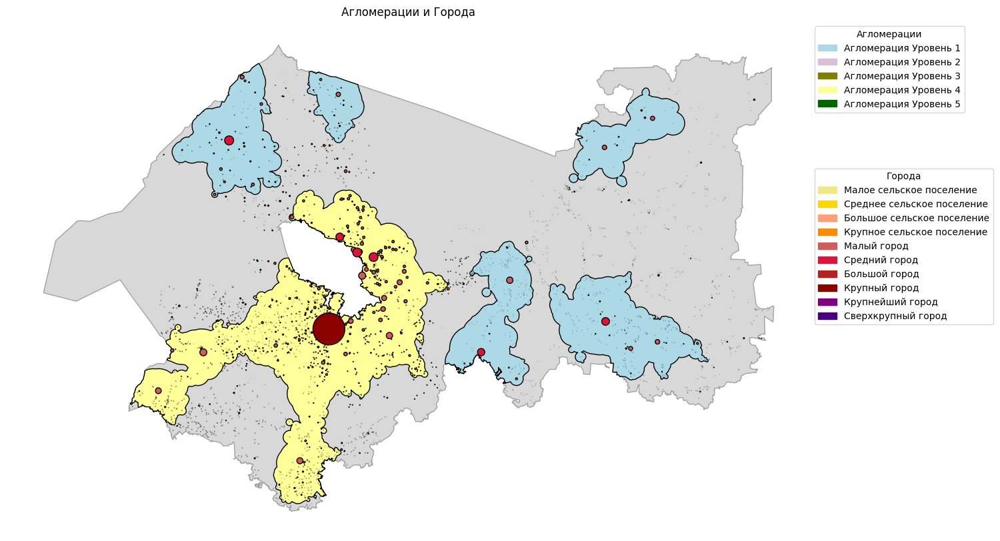

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Ваши цвета для агломераций
agglomeration_colors = {
    1: "#ADD8E6",  # светло-голубой
    2: "#D8BFD8",  # светло-фиолетовый
    3: "#808000",  # оливковый
    4: "#FFFF99",  # светло-желтый
    5: "#006400"   # темно-зеленый
}

# Ваши цвета для городов
city_colors = {
    "Малое сельское поселение": "#F0E68C",  # бледно-желтый
    "Среднее сельское поселение": "#FFD700",  # золотисто-желтый
    "Большое сельское поселение": "#FFA07A",  # светло-лососевый
    "Крупное сельское поселение": "#FF8C00",  # темно-оранжевый
    "Малый город": "#CD5C5C",                 # красно-коричневый
    "Средний город": "#DC143C",               # красный кармин
    "Большой город": "#B22222",               # огненно-красный
    "Крупный город": "#8B0000",               # темно-красный
    "Крупнейший город": "#800080",            # фиолетовый
    "Сверхкрупный город": "#4B0082"           # индиго
}

# Чтение агломераций и городов из GeoDataFrame
gdf_agglomerations = final_agglomerations
gdf_cities = cities
region_boundary = region_model.region  # Ваши границы региона

# Создание подложки для карты
fig, ax = plt.subplots(figsize=(20, 10))

# Визуализация границ региона (серым цветом с прозрачностью)
region_boundary.plot(ax=ax, color='gray', edgecolor='black', alpha=0.3)

# Визуализация агломераций
for level, color in agglomeration_colors.items():
    subset = gdf_agglomerations[gdf_agglomerations['agglomeration_level'] == level]
    subset.plot(ax=ax, color=color, edgecolor='black')

# Визуализация городов с различными цветами
for city_type, color in city_colors.items():
    subset = gdf_cities[gdf_cities['level'] == city_type]
    subset.plot(ax=ax, marker='o', color=color, markersize=10, edgecolor='black')

# Создание легенды для агломераций
agglomeration_patches = [mpatches.Patch(color=color, label=f'Агломерация Уровень {level}')
                         for level, color in agglomeration_colors.items()]

# Создание легенды для городов
city_patches = [mpatches.Patch(color=color, label=city_type)
                for city_type, color in city_colors.items()]

# Отображение легенды для агломераций
legend_agglomeration = plt.legend(handles=agglomeration_patches, loc='upper left', bbox_to_anchor=(1, 1), title="Агломерации")
ax.add_artist(legend_agglomeration)  # Добавление первой легенды

# Отображение легенды для городов
plt.legend(handles=city_patches, loc='lower left', bbox_to_anchor=(1, 0.4), title="Города")

# Настройка осей
plt.title("Агломерации и Города")
ax.set_axis_off()

# Показать карту
plt.show()

# Пространственное неравенство